# Entrenamiento, ajuste y evaluación de los cuatro modelos

Desarrollé los cuatro modelos del experimento, uno por bloque: **SVM**, **árbol de decisión**, **Random
Forest** (bagging) y **XGBoost** (boosting). Usé en todos las mismas particiones del notebook 03, los
evalué con las mismas métricas sobre el mismo conjunto de prueba y los medí con el mismo cronómetro, para
que las diferencias entre ellos vengan del modelo y no del procedimiento.

**Regla de oro del ajuste.** Elegí los hiperparámetros únicamente con datos de entrenamiento (validación
cruzada, evaluación out-of-bag o una partición interna de validación). Usé el conjunto de prueba una sola
vez por modelo, al final de su bloque, para reportar el resultado.

**Cómo medí el costo computacional.**

- *Tiempo de entrenamiento*: segundos que tarda el ajuste final del `Pipeline` completo (preprocesamiento
  más modelo) sobre las 36.168 filas de entrenamiento. Repetí el ajuste tres veces y reporté la mediana,
  junto con el mínimo y el máximo, porque el tiempo de una sola corrida cambia con la carga de la
  máquina. En los modelos con paralelismo interno usé un solo núcleo (`n_jobs=1`) en este paso, para que
  la comparación no dependa de cuántos núcleos tenga el equipo. La búsqueda de hiperparámetros sí usó
  todos los núcleos disponibles y su tiempo no forma parte del costo comparado.
- *Tiempo de predicción*: segundos que tarda `predict` del `Pipeline` completo sobre las 9.043 filas de
  prueba, también como mediana de varias repeticiones (tres en el SVM, que es lento, y más en los modelos
  rápidos).
- *Entorno*: registré el procesador, la memoria y las versiones de las librerías en `entorno.json`, porque
  los tiempos absolutos solo tienen sentido junto con la máquina donde se midieron.

**Cómo medí la estabilidad y el sesgo-varianza.** Además de las cinco métricas sobre prueba, calculé para
cada modelo un intervalo de confianza del 95 % por bootstrap sobre las predicciones de prueba (1000
remuestreos), las métricas sobre una muestra de entrenamiento del mismo tamaño que prueba (la brecha
entre ambas indica sobreajuste) y la proporción de clientes contratadores que queda dentro del 20 % de
clientes con mayor puntaje.

### Entorno y persistencia de resultados

En la celda siguiente fijé tres cosas que condicionan la reproducibilidad del experimento.

**Semilla fija.** Usé `RANDOM_STATE = 42` en la partición train/test y en el ajuste de todos los
modelos. Sin ella, cada ejecución produciría particiones distintas y las métricas no serían
comparables entre corridas ni verificables por un tercero.

**Persistencia en Google Drive.** Escribí los resultados en `MyDrive/bank_marketing` y no en el
disco temporal de Colab, que se borra al cerrar la sesión. El notebook 03 deja las particiones
preparadas y los notebooks 04 y 05 las consumen tal cual, de modo que todos operan sobre exactamente
los mismos datos. Si el montaje no se completa, la celda interrumpe la ejecución en lugar de escribir
en una ubicación volátil. Fuera de Colab no hace falta Drive, y los resultados se escriben en la
carpeta del repositorio (los gráficos en `splits/`).

**Registro de las figuras.** La función `guardar` escribe cada gráfico en `splits/` como PNG a 200
dpi. La invoco antes de `plt.show()`, porque mostrar la figura vacía el buffer de matplotlib y el
archivo saldría en blanco.

In [1]:
import os, io, time, json, zipfile, warnings, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

EN_DRIVE = False
try:
    from google.colab import drive
    drive.mount("/content/drive")
    if not os.path.isdir("/content/drive/MyDrive"):
        raise RuntimeError(
            "Drive no quedó montado. Vuelve a ejecutar esta celda y autoriza el acceso "
            "en la ventana emergente."
        )
    RUTA = "/content/drive/MyDrive/bank_marketing"
    EN_DRIVE = True
except ImportError:
    RUTA = os.path.abspath(".." if os.path.basename(os.getcwd()) == "notebooks" else ".")

CARPETA_SPLITS = os.path.join(RUTA, "splits")
os.makedirs(CARPETA_SPLITS, exist_ok=True)

def guardar(nombre):
    destino = os.path.join(CARPETA_SPLITS, nombre + ".png")
    plt.savefig(destino, dpi=200, bbox_inches="tight", facecolor="white")
    print("Gráfico guardado:", destino)

print("Guardando en Google Drive" if EN_DRIVE else "Google Drive no disponible: guardando localmente")
print("Ruta de trabajo:", RUTA)

Google Drive no disponible: guardando localmente
Ruta de trabajo: C:\Users\USUARIO\Documents\6_SEMESTRE\MACHINE LEARNING\Bank_Marketing\bank_marketing


## Preparación común

Cargué las particiones y definí los dos preprocesadores: el escalado (solo para el SVM, con el escalador
que eligió el notebook 03) y el no escalado (para los tres modelos de árboles). Los dos terminan en
one-hot de las categóricas. Ambos viven dentro de un `Pipeline`, así que se ajustan únicamente con los
datos de entrenamiento que reciba cada pipeline.

También separé una **muestra de entrenamiento del mismo tamaño que prueba** (9.043 filas). Evaluar sobre
ella, en vez de sobre todo el entrenamiento, mantiene el costo de predicción del SVM bajo control y
permite comparar la brecha entre entrenamiento y prueba con el mismo número de filas.

In [2]:
import joblib
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, RobustScaler, QuantileTransformer, OneHotEncoder
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split, cross_validate, cross_val_predict
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
from sklearn.dummy import DummyClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier
from xgboost import XGBClassifier

paquete = joblib.load(os.path.join(RUTA, "datos_preparados.joblib"))
X_train, X_test = paquete["X_train"], paquete["X_test"]
y_train, y_test = paquete["y_train"], paquete["y_test"]
cols_num, cols_cat = paquete["cols_num"], paquete["cols_cat"]
escalador_svm = paquete["escalador_svm"]
print("Train:", X_train.shape, "| Test:", X_test.shape, "| Escalador del SVM:", escalador_svm)

def codificador():
    return OneHotEncoder(handle_unknown="ignore", drop="if_binary")

def prep_sin_escalar():
    return ColumnTransformer([("num", "passthrough", cols_num), ("cat", codificador(), cols_cat)])

def prep_escalado():
    escaladores = {"estandar": StandardScaler(), "robusto": RobustScaler(),
                   "cuantil": QuantileTransformer(output_distribution="normal", n_quantiles=500, random_state=RANDOM_STATE)}
    return ColumnTransformer([("num", escaladores[escalador_svm], cols_num), ("cat", codificador(), cols_cat)])

validacion = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
puntuaciones = {"f1": "f1", "roc_auc": "roc_auc"}
X_tr_eval, _, y_tr_eval, _ = train_test_split(
    X_train, y_train, train_size=len(X_test), stratify=y_train, random_state=RANDOM_STATE)
peso_positivo = float((y_train == 0).sum() / (y_train == 1).sum())
print("Peso de la clase positiva (scale_pos_weight):", round(peso_positivo, 3))

Train: (36168, 18) | Test: (9043, 18) | Escalador del SVM: estandar
Peso de la clase positiva (scale_pos_weight): 7.548


## Funciones de medición

Escribí la función `registrar` para que la evaluación sea idéntica en los cuatro modelos. Cronometra
`predict`, calcula las cinco métricas sobre prueba, las mismas sobre la muestra de entrenamiento, el
bootstrap, la matriz de confusión y la captura del 20 % superior, y persiste todo en
`resultados_modelos.json` y `puntajes_test.npz`, que consume el notebook 05. Escribí también
`ajustar_midiendo`, que repite el ajuste final tres veces y devuelve el primer modelo junto con la
mediana y el rango de los tiempos. Por último, registré el entorno de ejecución (procesador, memoria y
versiones) en `entorno.json`.

**Umbral de decisión.** Cada modelo entrega un puntaje (la función de decisión en el SVM y una
probabilidad en los demás), y el umbral decide a partir de qué puntaje un cliente se marca como
contratador. El umbral por defecto (0 en el SVM y 0,5 en los demás) no tiene por qué ser el que maximiza el
F1, sobre todo con clases desbalanceadas. Por eso, en cada modelo, elegí el umbral que maximiza el F1 con
puntajes que el modelo no usó para entrenar (validación cruzada en el SVM y el árbol, out-of-bag en el
Random Forest y la partición interna de validación en XGBoost). La función `umbral_optimo` hace esa
búsqueda, y `registrar` reporta las métricas con el umbral elegido y también con el umbral por defecto,
para que se vea cuánto aporta este ajuste. El conjunto de prueba no interviene en la elección del umbral.

In [3]:
resultados, puntajes = {}, {}
os.makedirs(os.path.join(RUTA, "modelos"), exist_ok=True)

def puntaje(modelo, X):
    if hasattr(modelo, "predict_proba"):
        return modelo.predict_proba(X)[:, 1]
    return modelo.decision_function(X)

def metricas(y, prediccion, score):
    return {"accuracy": float(accuracy_score(y, prediccion)),
            "precision": float(precision_score(y, prediccion, zero_division=0)),
            "recall": float(recall_score(y, prediccion, zero_division=0)),
            "f1": float(f1_score(y, prediccion, zero_division=0)),
            "roc_auc": float(roc_auc_score(y, score))}

def bootstrap(y, prediccion, score, repeticiones=1000):
    generador = np.random.default_rng(RANDOM_STATE)
    y = np.asarray(y)
    f1s, aucs = [], []
    for _ in range(repeticiones):
        i = generador.integers(0, len(y), len(y))
        f1s.append(f1_score(y[i], prediccion[i], zero_division=0))
        aucs.append(roc_auc_score(y[i], score[i]))
    return {"ic95_f1": [float(np.percentile(f1s, 2.5)), float(np.percentile(f1s, 97.5))],
            "ic95_auc": [float(np.percentile(aucs, 2.5)), float(np.percentile(aucs, 97.5))],
            "desv_f1_bootstrap": float(np.std(f1s)), "desv_auc_bootstrap": float(np.std(aucs))}

def umbral_optimo(y, score):
    candidatos = np.unique(np.quantile(score, np.linspace(0.50, 0.98, 97)))
    f1s = [f1_score(y, score > u, zero_division=0) for u in candidatos]
    k = int(np.argmax(f1s))
    return float(candidatos[k]), float(f1s[k])

def captura_top20(y, score):
    y = np.asarray(y)
    mejores = np.argsort(-score)[: int(0.2 * len(y))]
    return float(y[mejores].sum() / y.sum())

def ajustar_midiendo(construir, repeticiones=3):
    tiempos, primero = [], None
    for _ in range(repeticiones):
        candidato = construir()
        inicio = time.perf_counter()
        candidato.fit(X_train, y_train)
        tiempos.append(time.perf_counter() - inicio)
        if primero is None:
            primero = candidato
    return primero, float(np.median(tiempos)), [float(min(tiempos)), float(max(tiempos))]

def persistir():
    with open(os.path.join(RUTA, "resultados_modelos.json"), "w", encoding="utf-8") as f:
        json.dump(resultados, f, ensure_ascii=False, indent=1)
    np.savez(os.path.join(RUTA, "puntajes_test.npz"), y_test=np.asarray(y_test), **puntajes)

def registrar(nombre, modelo, segundos_entrenamiento, repeticiones_prediccion, umbral, umbral_defecto, extra=None):
    tiempos, s_test = [], None
    for _ in range(repeticiones_prediccion):
        inicio = time.perf_counter()
        s = puntaje(modelo, X_test)
        tiempos.append(time.perf_counter() - inicio)
        if s_test is None:
            s_test = s
    prediccion = (s_test > umbral).astype(int)
    s_tr = puntaje(modelo, X_tr_eval)
    p_tr = (s_tr > umbral).astype(int)
    registro = {
        "umbral": float(umbral),
        "umbral_defecto": float(umbral_defecto),
        "test_umbral_defecto": metricas(y_test, (s_test > umbral_defecto).astype(int), s_test),
        "tiempo_entrenamiento_s": float(segundos_entrenamiento),
        "tiempo_prediccion_s": float(np.median(tiempos)),
        "rango_prediccion_s": [float(min(tiempos)), float(max(tiempos))],
        "clientes_predichos": int(len(X_test)),
        "test": metricas(y_test, prediccion, s_test),
        "train_muestra": metricas(y_tr_eval, p_tr, s_tr),
        "matriz_confusion": confusion_matrix(y_test, prediccion).tolist(),
        "captura_top20": captura_top20(y_test, s_test),
    }
    registro.update(bootstrap(y_test, prediccion, s_test))
    if extra:
        registro.update(extra)
    resultados[nombre] = registro
    puntajes[nombre] = s_test
    persistir()
    joblib.dump(modelo, os.path.join(RUTA, "modelos", nombre + ".joblib"), compress=3)
    t = registro["test"]
    print(f"{nombre}: umbral ajustado {umbral:.3f} (por defecto {umbral_defecto}) | F1 en prueba con el umbral por defecto "
          f"{registro['test_umbral_defecto']['f1']:.4f}")
    print(f"{nombre}: entrenamiento {registro['tiempo_entrenamiento_s']:.2f} s | predicción {registro['tiempo_prediccion_s']:.3f} s")
    print(f"  test -> accuracy {t['accuracy']:.4f} | precision {t['precision']:.4f} | recall {t['recall']:.4f} | "
          f"F1 {t['f1']:.4f} | AUC {t['roc_auc']:.4f}")
    print(f"  train (muestra) -> F1 {registro['train_muestra']['f1']:.4f} | AUC {registro['train_muestra']['roc_auc']:.4f}")
    print(f"  IC 95 % F1 {registro['ic95_f1'][0]:.4f} a {registro['ic95_f1'][1]:.4f} | captura top 20 % {registro['captura_top20']:.3f}")

def importancia_por_variable(preparador, valores):
    acumulado = {}
    for nombre, valor in zip(preparador.get_feature_names_out(), valores):
        origen = nombre.split("__", 1)[1]
        for col in cols_cat:
            if nombre.startswith("cat__" + col + "_"):
                origen = col
                break
        acumulado[origen] = acumulado.get(origen, 0.0) + float(valor)
    return pd.Series(acumulado).sort_values(ascending=False)

def graficar_importancia(serie, titulo, archivo, color):
    tope = serie.head(12).sort_values()
    plt.figure(figsize=(7, 5))
    plt.barh(tope.index, tope.values, color=color)
    plt.xlabel("Importancia (suma por variable original)")
    plt.title(titulo)
    plt.tight_layout()
    guardar(archivo)
    plt.show()

In [4]:
import platform, sys
import sklearn, xgboost
try:
    import psutil
    memoria_gb = round(psutil.virtual_memory().total / 2 ** 30, 1)
except ImportError:
    memoria_gb = None

entorno = {"sistema": platform.platform(), "procesador": platform.processor(), "nucleos_logicos": os.cpu_count(),
           "memoria_gb": memoria_gb, "python": sys.version.split()[0], "numpy": np.__version__,
           "pandas": pd.__version__, "scikit_learn": sklearn.__version__, "xgboost": xgboost.__version__}
with open(os.path.join(RUTA, "entorno.json"), "w", encoding="utf-8") as f:
    json.dump(entorno, f, ensure_ascii=False, indent=1)
for clave, valor in entorno.items():
    print(f"{clave}: {valor}")

sistema: Windows-11-10.0.26200-SP0
procesador: Intel64 Family 6 Model 154 Stepping 3, GenuineIntel
nucleos_logicos: 16
memoria_gb: 31.7
python: 3.12.10
numpy: 2.2.6
pandas: 3.0.3
scikit_learn: 1.8.0
xgboost: 3.4.1


## Línea base

Registré un clasificador que siempre responde `no` como piso, porque cualquier modelo que no lo supere en
F1 y en AUC no aporta nada. Lo evalué con el mismo procedimiento que los demás, para que el costo de
referencia (prácticamente cero) también quede en la tabla.

In [5]:
base = DummyClassifier(strategy="most_frequent")
inicio = time.perf_counter()
base.fit(X_train, y_train)
registrar("Baseline", base, time.perf_counter() - inicio, 5, 0.5, 0.5)

Baseline: umbral ajustado 0.500 (por defecto 0.5) | F1 en prueba con el umbral por defecto 0.0000
Baseline: entrenamiento 0.00 s | predicción 0.000 s
  test -> accuracy 0.8830 | precision 0.0000 | recall 0.0000 | F1 0.0000 | AUC 0.5000
  train (muestra) -> F1 0.0000 | AUC 0.5000
  IC 95 % F1 0.0000 a 0.0000 | captura top 20 % 0.207


**Lectura.** La línea base tiene F1 y AUC de piso (0 y 0,5), accuracy de 0,883 y un costo
prácticamente nulo. Ningún modelo debe compararse contra la accuracy de este modelo, sino contra su F1
y su AUC.

# Bloque 1: Máquina de vectores de soporte (SVM)

### Decisiones de diseño

**Kernel.** No asumí el kernel, lo comparé. El kernel lineal es el más barato y sirve de referencia; el
RBF puede curvar la frontera con un solo parámetro de forma (`gamma`); el polinómico agrega interacciones
explícitas de un grado dado. Los tres entraron en la misma búsqueda y la validación cruzada decidió, con
una tabla que permite ver cuánto gana cada uno sobre el lineal.

**Hiperparámetros.** `C` controla la penalización por errores de entrenamiento (valores altos ajustan
más y arriesgan sobreajuste) y `gamma` el alcance de cada punto en los kernels RBF y polinómico
(valores altos hacen fronteras más locales). Los busqué en rejilla con validación cruzada estratificada
de 5 particiones y seleccioné por F1 de la clase positiva.

**Submuestra para la búsqueda.** Un SVM con kernel tiene costo entre cuadrático y cúbico en el número
de filas. Buscar sobre las 36.168 filas multiplicaría el tiempo por decenas, así que evalué la rejilla
sobre una submuestra estratificada de 6.000 filas y reentrené el modelo final con todo el
entrenamiento. La limitación es real: con más datos, el valor óptimo de `C` tiende a subir levemente,
y el tiempo de búsqueda no es comparable con el de los demás modelos.

**Ponderación.** `class_weight="balanced"` hace que un error sobre un contratador pese como el
desbalance (aproximadamente 7,5 veces). Lo contrasté más abajo con el modelo sin ponderar.

**Tope de iteraciones.** Puse `max_iter` para evitar que un `C` alto con kernel lineal o polinómico deje
la búsqueda colgada. Si una combinación no converge dentro del tope, simplemente sale con peor puntaje.

In [6]:
submuestra_svm, _, y_submuestra_svm, _ = train_test_split(
    X_train, y_train, train_size=6000, stratify=y_train, random_state=RANDOM_STATE)

pipe_svm = Pipeline([
    ("prep", prep_escalado()),
    ("clf", SVC(class_weight="balanced", max_iter=300000, random_state=RANDOM_STATE))])

rejilla_svm = [
    {"clf__kernel": ["linear"], "clf__C": [0.01, 0.1, 1]},
    {"clf__kernel": ["rbf"], "clf__C": [0.3, 1, 3, 10], "clf__gamma": [0.001, 0.003, 0.01, 0.03, 0.1]},
    {"clf__kernel": ["poly"], "clf__degree": [2, 3], "clf__C": [0.1, 0.3, 1, 3], "clf__gamma": [0.01, 0.03, 0.1]},
]

busqueda_svm = GridSearchCV(pipe_svm, rejilla_svm, scoring=puntuaciones, refit="f1",
                            cv=validacion, n_jobs=-1)
inicio = time.perf_counter()
busqueda_svm.fit(submuestra_svm, y_submuestra_svm)
segundos_busqueda_svm = time.perf_counter() - inicio

cv_svm = pd.DataFrame(busqueda_svm.cv_results_)
mejor_por_kernel = (cv_svm.groupby("param_clf__kernel")[["mean_test_f1", "mean_test_roc_auc"]].max().round(4)
                    .rename(columns={"mean_test_f1": "mejor_f1_cv", "mean_test_roc_auc": "mejor_auc_cv"}))
print(mejor_por_kernel, "\n")
print("Mejores hiperparámetros:", busqueda_svm.best_params_)
print("F1 en validación cruzada:", round(busqueda_svm.best_score_, 4))
print("Tiempo de búsqueda:", round(segundos_busqueda_svm, 1), "s sobre 6000 filas")

                   mejor_f1_cv  mejor_auc_cv
param_clf__kernel                           
linear                  0.3456        0.7259
poly                    0.3931        0.7387
rbf                     0.3951        0.7428 

Mejores hiperparámetros: {'clf__C': 1, 'clf__gamma': 0.03, 'clf__kernel': 'rbf'}
F1 en validación cruzada: 0.3951
Tiempo de búsqueda: 248.5 s sobre 6000 filas


**Lectura.** El kernel RBF es el mejor de los tres, aunque por poco. En validación cruzada obtiene un F1
de 0,395 y un AUC de 0,743, contra 0,393 y 0,739 del polinómico y 0,346 y 0,726 del lineal. La ventaja
sobre el lineal (cerca de 5 puntos de F1) justifica un kernel no lineal. Entre el RBF y el polinómico la
diferencia es pequeña, pero el RBF gana en las dos métricas y tiene un solo parámetro de forma, así que
me quedé con él. La combinación elegida es `C = 1` y `gamma = 0,03`. La búsqueda sobre 6.000 filas tomó
unos cuatro minutos.

Gráfico guardado: C:\Users\USUARIO\Documents\6_SEMESTRE\MACHINE LEARNING\Bank_Marketing\bank_marketing\splits\04_svm_rejilla_c_gamma.png


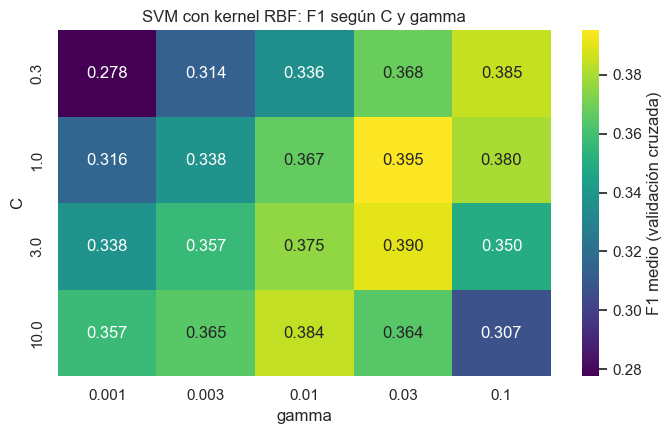

In [7]:
kernel_svm = busqueda_svm.best_params_["clf__kernel"]
ganador = cv_svm[cv_svm["param_clf__kernel"] == kernel_svm]
if kernel_svm == "poly":
    ganador = ganador[ganador["param_clf__degree"] == busqueda_svm.best_params_["clf__degree"]]
matriz_f1 = ganador.pivot_table(index="param_clf__C", columns="param_clf__gamma", values="mean_test_f1")
nombre_kernel = "RBF" if kernel_svm == "rbf" else f"polinómico de grado {busqueda_svm.best_params_['clf__degree']}"

plt.figure(figsize=(7, 4.5))
sns.heatmap(matriz_f1, annot=True, fmt=".3f", cmap="viridis", cbar_kws={"label": "F1 medio (validación cruzada)"})
plt.xlabel("gamma")
plt.ylabel("C")
plt.title(f"SVM con kernel {nombre_kernel}: F1 según C y gamma")
plt.tight_layout()
guardar("04_svm_rejilla_c_gamma")
plt.show()

**Lectura.** El mapa muestra una zona buena con `gamma` entre 0,01 y 0,03 y `C` entre 1 y 3 (F1 de 0,375
a 0,395). Con `gamma = 0,1` el F1 baja en casi todas las filas (hasta 0,307 con `C = 10`), y lo mismo
pasa con `C = 10` y `gamma` alto, porque la frontera se vuelve demasiado local y el modelo se sobreajusta.
Como el mejor valor quedó en el interior de la rejilla y no en su borde, la búsqueda cubrió el rango
necesario.

### Efecto de la ponderación de clases

Repetí la validación cruzada con los mejores hiperparámetros, con y sin `class_weight="balanced"`, sobre
la misma submuestra. Si la ponderación no mejora el F1 o el recall de la clase positiva, no hay razón
para mantenerla.

In [8]:
filas = []
for etiqueta, peso in [("sin ponderar", None), ("balanced", "balanced")]:
    modelo = clone(pipe_svm).set_params(**busqueda_svm.best_params_, clf__class_weight=peso)
    r = cross_validate(modelo, submuestra_svm, y_submuestra_svm, cv=validacion,
                       scoring=["f1", "recall", "precision", "roc_auc"], n_jobs=-1)
    filas.append({"ponderación": etiqueta, "f1": r["test_f1"].mean(), "recall": r["test_recall"].mean(),
                  "precision": r["test_precision"].mean(), "auc": r["test_roc_auc"].mean()})
pd.DataFrame(filas).set_index("ponderación").round(4)

,f1,recall,precision,auc
ponderación,,,,
sin ponderar,0.2630,0.1652,0.6497,0.6929
balanced,0.3951,0.5625,0.3054,0.7409


**Lectura.** La ponderación de clases cambia por completo el modelo. Sin ponderar, el SVM casi no
detecta contratadores (recall de 0,165) y el F1 queda en 0,263. Con `balanced` el recall sube a 0,563 y
el F1 a 0,395. También mejora el AUC (de 0,693 a 0,741), es decir que no solo mueve el umbral sino que
ordena mejor a los clientes. Conservé la ponderación.

### Modelo final y costo

Elegí el umbral con las predicciones de validación cruzada sobre la misma submuestra de 6.000 clientes,
porque repetir la validación cruzada sobre todo el entrenamiento multiplicaría el costo. Después
reentrené el pipeline completo con los hiperparámetros elegidos sobre **todo** el entrenamiento y medí el
tiempo de ese ajuste. Es la parte más cara del experimento.

In [9]:
puntaje_cv_svm = cross_val_predict(clone(pipe_svm).set_params(**busqueda_svm.best_params_), submuestra_svm,
                                   y_submuestra_svm, cv=validacion, method="decision_function", n_jobs=-1)
umbral_svm, f1_cv_svm = umbral_optimo(y_submuestra_svm, puntaje_cv_svm)
print(f"Umbral elegido por validación cruzada: {umbral_svm:.3f} (F1 de validación {f1_cv_svm:.4f})")

svm_final, segundos_svm, rango_svm = ajustar_midiendo(
    lambda: clone(pipe_svm).set_params(**busqueda_svm.best_params_))

soporte = int(svm_final.named_steps["clf"].n_support_.sum())
registrar("SVM", svm_final, segundos_svm, 3, umbral_svm, 0.0,
          extra={"rango_entrenamiento_s": rango_svm, "parametros": {k: (v if not isinstance(v, np.generic) else v.item()) for k, v in busqueda_svm.best_params_.items()},
                 "vectores_soporte": soporte, "segundos_busqueda": float(segundos_busqueda_svm)})
print("Vectores de soporte:", soporte, f"({100 * soporte / len(X_train):.1f} % del entrenamiento)")

Umbral elegido por validación cruzada: 0.464 (F1 de validación 0.4135)


SVM: umbral ajustado 0.464 (por defecto 0.0) | F1 en prueba con el umbral por defecto 0.4580
SVM: entrenamiento 96.64 s | predicción 44.382 s
  test -> accuracy 0.8704 | precision 0.4531 | recall 0.5208 | F1 0.4846 | AUC 0.7907
  train (muestra) -> F1 0.4930 | AUC 0.7994
  IC 95 % F1 0.4587 a 0.5091 | captura top 20 % 0.612
Vectores de soporte: 22502 (62.2 % del entrenamiento)


**Lectura.** Con el umbral elegido por validación cruzada (0,464 en la función de decisión, en lugar de
0), el SVM obtuvo en prueba un F1 de 0,485 y un AUC de 0,791. Con el umbral por defecto el F1 habría sido
0,458, así que el ajuste aportó casi 3 puntos. Su brecha con el entrenamiento es mínima (F1 de 0,493 en
la muestra de entrenamiento), señal de un modelo bien regularizado. Su costo es el más alto del
experimento. El entrenamiento tarda más de un minuto y medio y la predicción sobre 9.043 clientes tarda
decenas de segundos (unos 5 milisegundos por cliente, frente a microsegundos del árbol). El 62 % de los
clientes de entrenamiento terminó como vector de soporte, y eso explica por qué cada predicción es cara,
porque debe compararse con todos ellos.

# Bloque 2: Árbol de decisión

### Decisiones de diseño

**Criterio de impureza.** `gini` y `entropy` miden qué tan mezclada queda una partición. Casi siempre
dan árboles parecidos, pero los comparé en la misma búsqueda en lugar de suponer que da igual.

**Control del sobreajuste.** Un árbol sin límites sigue dividiendo hasta memorizar cada fila de
entrenamiento. Lo frené con dos palancas, `max_depth` (cuántas preguntas encadenadas puede hacer) y
`min_samples_leaf` (cuántos clientes como mínimo debe tener cada hoja). Ambas entraron en la rejilla, y
grafiqué el F1 de entrenamiento contra el de validación para ver dónde empieza la brecha.

**Sin escalado.** Le di las numéricas tal cual, por lo demostrado en el notebook 03.

**Ponderación.** Usé `class_weight="balanced"` y lo contrasté contra el modelo sin ponderar con
validación cruzada.

In [10]:
pipe_arbol = Pipeline([
    ("prep", prep_sin_escalar()),
    ("clf", DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE))])

rejilla_arbol = {
    "clf__criterion": ["gini", "entropy"],
    "clf__max_depth": [3, 4, 5, 6, 8, 10, 15, None],
    "clf__min_samples_leaf": [1, 5, 20, 50, 100],
}

busqueda_arbol = GridSearchCV(pipe_arbol, rejilla_arbol, scoring=puntuaciones, refit="f1",
                              cv=validacion, n_jobs=-1, return_train_score=True)
busqueda_arbol.fit(X_train, y_train)

cv_arbol = pd.DataFrame(busqueda_arbol.cv_results_)
print("Mejores hiperparámetros:", busqueda_arbol.best_params_)
print("F1 en validación cruzada:", round(busqueda_arbol.best_score_, 4))

sin_control = cv_arbol[(cv_arbol["param_clf__max_depth"].isna()) & (cv_arbol["param_clf__min_samples_leaf"] == 1)]
print("\nÁrbol sin control del sobreajuste (max_depth=None, min_samples_leaf=1):")
print(sin_control[["param_clf__criterion", "mean_train_f1", "mean_test_f1"]].round(4).to_string(index=False))

Mejores hiperparámetros: {'clf__criterion': 'entropy', 'clf__max_depth': 6, 'clf__min_samples_leaf': 20}
F1 en validación cruzada: 0.4626

Árbol sin control del sobreajuste (max_depth=None, min_samples_leaf=1):
param_clf__criterion  mean_train_f1  mean_test_f1
                gini            1.0        0.3112
             entropy            1.0        0.3105


**Lectura.** La mejor combinación es criterio `entropy`, profundidad máxima 6 y al menos 20 clientes por
hoja, con un F1 de 0,463 en validación cruzada. El árbol sin ningún control memoriza el entrenamiento
(F1 de 1,00) pero cae a 0,311 en validación con los dos criterios. Controlar el sobreajuste le hace ganar
15 puntos de F1.

Gráfico guardado: C:\Users\USUARIO\Documents\6_SEMESTRE\MACHINE LEARNING\Bank_Marketing\bank_marketing\splits\04_arbol_sobreajuste.png


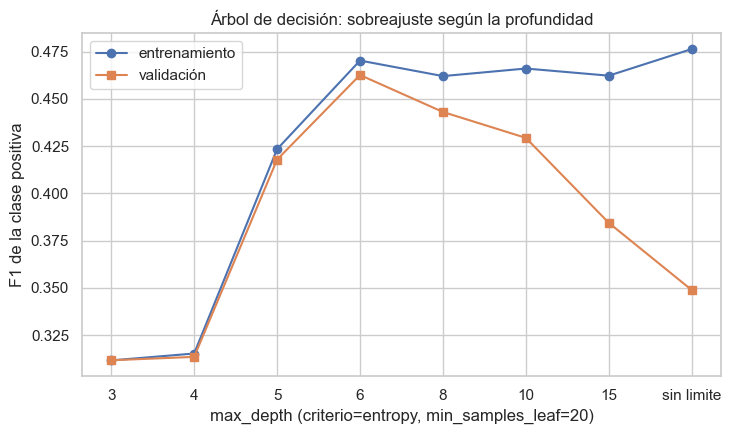

In [11]:
criterio = busqueda_arbol.best_params_["clf__criterion"]
hoja = busqueda_arbol.best_params_["clf__min_samples_leaf"]
curva = cv_arbol[(cv_arbol["param_clf__criterion"] == criterio) & (cv_arbol["param_clf__min_samples_leaf"] == hoja)].copy()
curva["profundidad"] = curva["param_clf__max_depth"].apply(lambda v: 40 if pd.isna(v) else v)
curva = curva.sort_values("profundidad")
etiquetas = [("sin limite" if p == 40 else int(p)) for p in curva["profundidad"]]

plt.figure(figsize=(7.5, 4.5))
plt.plot(range(len(curva)), curva["mean_train_f1"], marker="o", label="entrenamiento")
plt.plot(range(len(curva)), curva["mean_test_f1"], marker="s", label="validación")
plt.xticks(range(len(curva)), etiquetas)
plt.xlabel(f"max_depth (criterio={criterio}, min_samples_leaf={hoja})")
plt.ylabel("F1 de la clase positiva")
plt.title("Árbol de decisión: sobreajuste según la profundidad")
plt.legend()
plt.tight_layout()
guardar("04_arbol_sobreajuste")
plt.show()

**Lectura.** La curva de validación sube con la profundidad hasta 6 y luego baja (0,430 con profundidad
10, 0,385 con 15 y 0,349 sin límite), mientras el F1 de entrenamiento se mantiene alto. La separación
entre las dos líneas es la huella visual del sobreajuste, y el punto donde la validación deja de mejorar
es el que elegí. Con las variables de fecha el árbol óptimo es más corto que antes, porque `dia_del_anio`
le permite aislar los períodos buenos de la campaña con menos preguntas.

In [12]:
filas = []
for etiqueta, peso in [("sin ponderar", None), ("balanced", "balanced")]:
    modelo = clone(pipe_arbol).set_params(**busqueda_arbol.best_params_, clf__class_weight=peso)
    r = cross_validate(modelo, X_train, y_train, cv=validacion, scoring=["f1", "recall", "precision", "roc_auc"], n_jobs=-1)
    filas.append({"ponderación": etiqueta, "f1": r["test_f1"].mean(), "recall": r["test_recall"].mean(),
                  "precision": r["test_precision"].mean(), "auc": r["test_roc_auc"].mean()})
pd.DataFrame(filas).set_index("ponderación").round(4)

,f1,recall,precision,auc
ponderación,,,,
sin ponderar,0.2787,0.1773,0.6556,0.7333
balanced,0.4626,0.4940,0.4353,0.7506


**Lectura.** La ponderación sube el F1 de 0,279 a 0,463 y el recall de 0,177 a 0,494, a costa de bajar la
precisión (de 0,656 a 0,435). El AUC también mejora (0,733 a 0,751). Conservé la ponderación.

### Modelo final, costo e interpretación

Elegí el umbral con las probabilidades de validación cruzada de 5 particiones sobre el entrenamiento y
ajusté el árbol con los mejores hiperparámetros sobre todo el entrenamiento. La interpretación tiene dos
partes. Una es el diagrama de los primeros niveles, que muestra las preguntas concretas que hace el
modelo. La otra es la importancia de variables, que agregué por variable original (las columnas one-hot
de una misma categórica se suman para que `job` aparezca como una sola variable y no como doce).

In [13]:
puntaje_cv_arbol = cross_val_predict(clone(pipe_arbol).set_params(**busqueda_arbol.best_params_), X_train, y_train,
                                     cv=validacion, method="predict_proba", n_jobs=-1)[:, 1]
umbral_arbol, f1_cv_arbol = umbral_optimo(y_train, puntaje_cv_arbol)
print(f"Umbral elegido por validación cruzada: {umbral_arbol:.3f} (F1 de validación {f1_cv_arbol:.4f})")

arbol_final, segundos_arbol, rango_arbol = ajustar_midiendo(
    lambda: clone(pipe_arbol).set_params(**busqueda_arbol.best_params_))

clf_arbol = arbol_final.named_steps["clf"]
registrar("Arbol", arbol_final, segundos_arbol, 20, umbral_arbol, 0.5,
          extra={"rango_entrenamiento_s": rango_arbol, "parametros": {k: (None if (isinstance(v, float) and np.isnan(v)) else v) for k, v in busqueda_arbol.best_params_.items()},
                 "profundidad": int(clf_arbol.get_depth()), "hojas": int(clf_arbol.get_n_leaves())})
print("Profundidad real:", clf_arbol.get_depth(), "| Hojas:", clf_arbol.get_n_leaves())

Umbral elegido por validación cruzada: 0.670 (F1 de validación 0.4669)


Arbol: umbral ajustado 0.670 (por defecto 0.5) | F1 en prueba con el umbral por defecto 0.4723
Arbol: entrenamiento 0.68 s | predicción 0.070 s
  test -> accuracy 0.8796 | precision 0.4852 | recall 0.4792 | F1 0.4822 | AUC 0.7592
  train (muestra) -> F1 0.4552 | AUC 0.7454
  IC 95 % F1 0.4553 a 0.5093 | captura top 20 % 0.561
Profundidad real: 6 | Hojas: 44


**Lectura.** El árbol final tiene profundidad 6 y 44 hojas. Con el umbral elegido por validación cruzada
(0,670) obtuvo en prueba un F1 de 0,482, contra 0,472 con el umbral de 0,5. Su AUC es el más bajo de los
cuatro (0,759), porque un árbol de 44 hojas solo puede dar 44 puntajes distintos y ordena a los clientes
de forma gruesa. Entrena en menos de un segundo y predice los 9.043 clientes en centésimas de segundo.
No muestra sobreajuste (F1 de 0,455 en la muestra de entrenamiento contra 0,482 en prueba).

Gráfico guardado: C:\Users\USUARIO\Documents\6_SEMESTRE\MACHINE LEARNING\Bank_Marketing\bank_marketing\splits\04_arbol_estructura.png


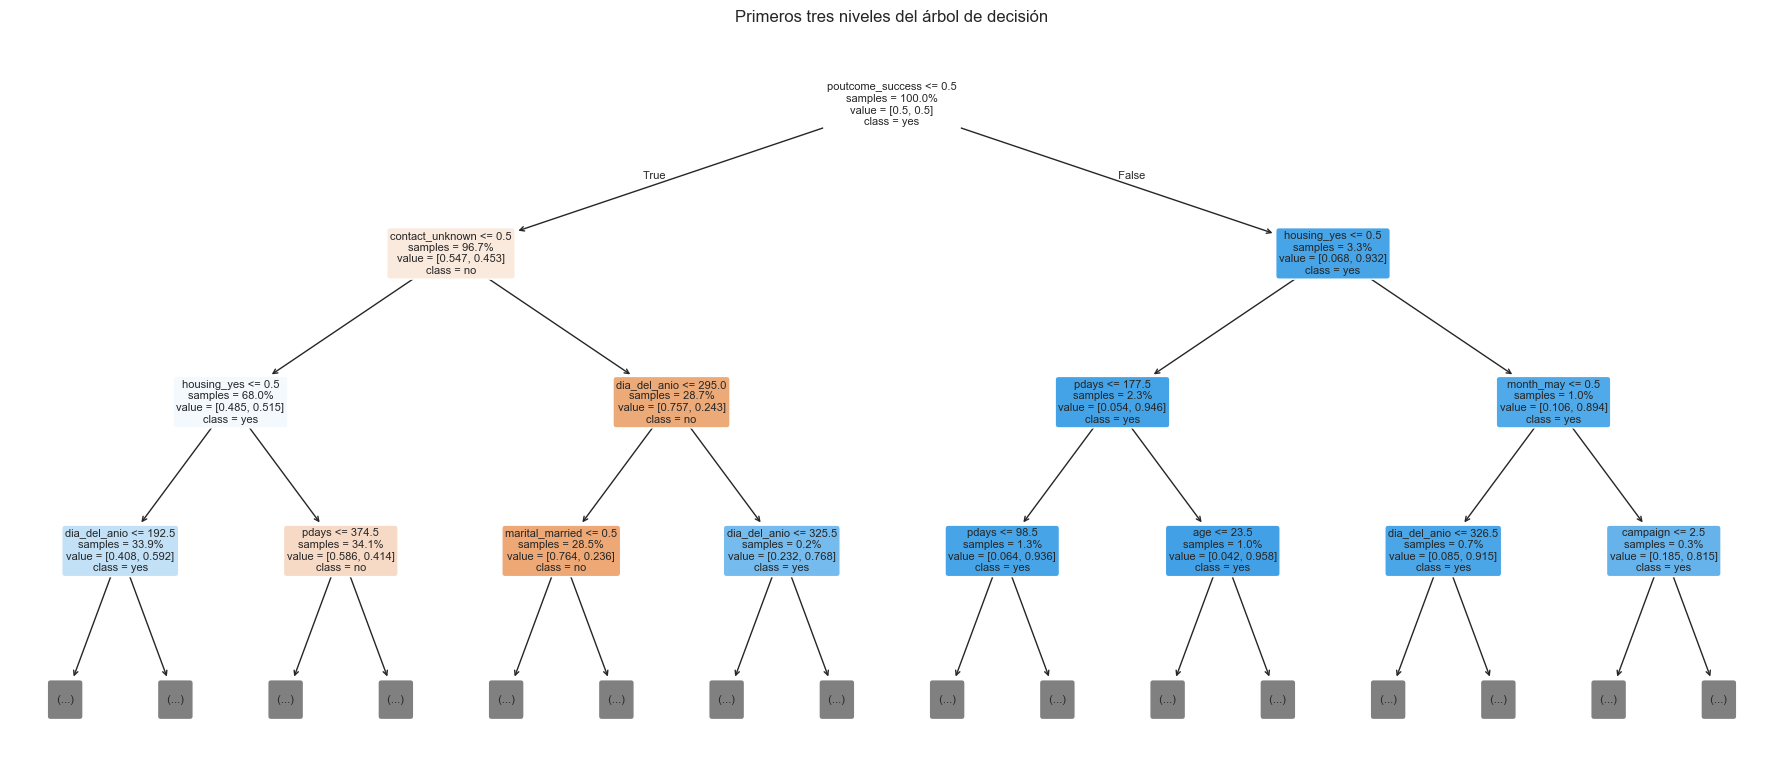

poutcome        0.3531
dia_del_anio    0.2481
contact         0.1814
housing         0.0824
pdays           0.0539
month           0.0518
marital         0.0125
balance         0.0055
age             0.0050
day             0.0038
dtype: float64


Gráfico guardado: C:\Users\USUARIO\Documents\6_SEMESTRE\MACHINE LEARNING\Bank_Marketing\bank_marketing\splits\04_arbol_importancia.png


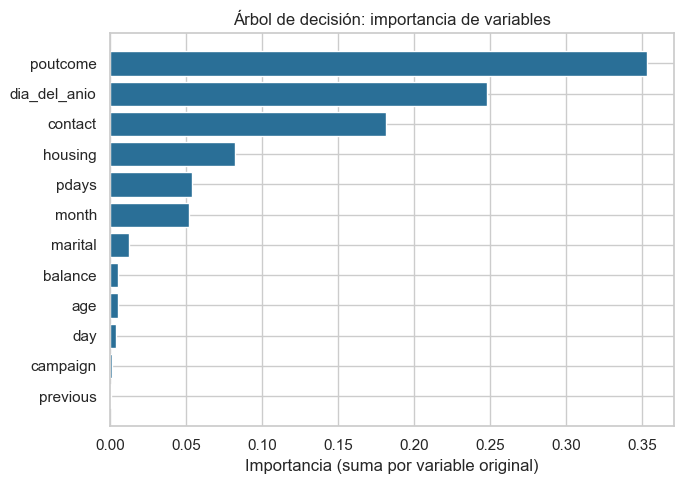

In [14]:
nombres_columnas = [n.split("__", 1)[1] for n in arbol_final.named_steps["prep"].get_feature_names_out()]
plt.figure(figsize=(18, 8))
plot_tree(clf_arbol, max_depth=3, feature_names=nombres_columnas, class_names=["no", "yes"],
          filled=True, rounded=True, fontsize=8, proportion=True, impurity=False)
plt.title("Primeros tres niveles del árbol de decisión")
plt.tight_layout()
guardar("04_arbol_estructura")
plt.show()

importancia_arbol = importancia_por_variable(arbol_final.named_steps["prep"], clf_arbol.feature_importances_)
resultados["Arbol"]["importancia"] = {k: float(v) for k, v in importancia_arbol.items()}
persistir()
print(importancia_arbol.head(10).round(4))
graficar_importancia(importancia_arbol, "Árbol de decisión: importancia de variables", "04_arbol_importancia", "#2a6f97")

**Lectura.** El árbol se apoya sobre todo en `poutcome` (35,3 %), `dia_del_anio` (24,8 %) y `contact`
(18,1 %), y la primera pregunta que hace es si la campaña anterior tuvo éxito. La variable de fecha que
agregué en el notebook 03 es la segunda más usada, lo que confirma que la época de la llamada importa.
En el diagrama los valores aparecen como proporciones con el peso de clases aplicado, por eso la raíz
muestra 0,5 y 0,5 aunque los contratadores sean el 11,7 % real. El árbol es la única familia que se puede
explicar a un gerente como reglas.

# Bloque 3: Random Forest (bagging) y evaluación out-of-bag

### Decisiones de diseño

**Por qué Random Forest y no solo bagging.** El bagging promedia árboles entrenados con remuestreos
distintos, y eso reduce la varianza. Random Forest añade un paso más: en cada división solo considera
un subconjunto aleatorio de variables (`max_features`), lo que decorrelaciona los árboles y hace que
el promedio reduzca más varianza. Es la versión del bagging que se usa en la práctica.

**Evaluación out-of-bag (OOB).** Cada árbol se entrena con un remuestreo en el que queda sin usar,
en promedio, el 36,8 % de las filas. Cada fila se predice con los árboles que no la vieron, y eso da
una estimación honesta del desempeño sin separar un conjunto de validación. Hice la búsqueda de
hiperparámetros **con OOB** y no con validación cruzada, porque es más barato (un solo ajuste por
combinación) y es la técnica propia de este modelo.

**Hiperparámetros.** Exploré `max_features` (cuántas variables ve cada división) y `min_samples_leaf`
(el límite del tamaño de las hojas, que controla qué tan profundos y ruidosos son los árboles). Fijé el
número de árboles en 300 y lo verifiqué después con la curva OOB.

**Ponderación.** `class_weight="balanced_subsample"` recalcula los pesos dentro de cada remuestreo, que
es la forma correcta de ponderar en un bosque.

In [15]:
preparador_rf = prep_sin_escalar().fit(X_train)
Xt_rf = preparador_rf.transform(X_train)

def ajustar_rf(maximo, hoja, peso="balanced_subsample", arboles=300, nucleos=-1, semilla=RANDOM_STATE):
    return RandomForestClassifier(n_estimators=arboles, max_features=maximo, min_samples_leaf=hoja,
                                  class_weight=peso, oob_score=True, n_jobs=nucleos,
                                  random_state=semilla).fit(Xt_rf, y_train)

def resumen_oob(bosque):
    oob = np.nan_to_num(bosque.oob_decision_function_[:, 1], nan=0.0)
    return float(f1_score(y_train, oob > 0.5)), float(roc_auc_score(y_train, oob)), float(bosque.oob_score_)

filas = []
for maximo in ["sqrt", 0.2, 0.4]:
    for hoja in [1, 3, 5, 10, 20]:
        inicio = time.perf_counter()
        bosque = ajustar_rf(maximo, hoja)
        f1_oob, auc_oob, acc_oob = resumen_oob(bosque)
        filas.append({"max_features": maximo, "min_samples_leaf": hoja, "f1_oob": f1_oob,
                      "auc_oob": auc_oob, "accuracy_oob": acc_oob, "segundos": time.perf_counter() - inicio})

busqueda_rf = pd.DataFrame(filas)
print(busqueda_rf.round(4).to_string(index=False))
mejor_rf = busqueda_rf.loc[busqueda_rf["f1_oob"].idxmax()]
print("\nMejor combinación según F1 OOB:")
print(mejor_rf.to_string())

max_features  min_samples_leaf  f1_oob  auc_oob  accuracy_oob  segundos
        sqrt                 1  0.3381   0.7820        0.8934   10.4794
        sqrt                 3  0.4800   0.7962        0.8764   10.4438
        sqrt                 5  0.4890   0.8010        0.8660   10.4663
        sqrt                10  0.4870   0.8034        0.8563    9.5600
        sqrt                20  0.4778   0.8026        0.8461    9.9757
         0.2                 1  0.3354   0.7802        0.8924   11.6469
         0.2                 3  0.4755   0.7972        0.8805   11.7512
         0.2                 5  0.4894   0.7992        0.8702   10.9387
         0.2                10  0.4877   0.8022        0.8589   11.0169
         0.2                20  0.4783   0.8029        0.8485   10.5050
         0.4                 1  0.3459   0.7820        0.8931   15.0808
         0.4                 3  0.4574   0.7914        0.8853   14.5344
         0.4                 5  0.4840   0.7966        0.8757   

**Lectura.** El OOB muestra que el tamaño de las hojas es la decisión clave. Con hojas de un solo cliente
el F1 OOB es de solo 0,34 a 0,35, porque el bosque memoriza y sus probabilidades casi nunca pasan de 0,5.
Con hojas de 5 a 10 clientes sube a 0,48 y 0,49. La mejor combinación es `max_features = 0,2` y
`min_samples_leaf = 5` (F1 OOB 0,489 y AUC OOB 0,799), aunque las combinaciones con hojas de 5 a 10
difieren en menos de un punto. Usar el 40 % de las variables cuesta un 30 % más de tiempo sin mejorar.

### Del árbol al bagging y al Random Forest

Para ver qué aporta cada paso, comparé tres modelos. Un árbol sin control memoriza el entrenamiento. El
**bagging** promedia muchos árboles de ese tipo, cada uno entrenado con un remuestreo, y eso reduce la
varianza. El **Random Forest** agrega además la selección aleatoria de variables en cada división. Los
medí con la misma métrica fuera de muestra (validación cruzada para el árbol, OOB para los conjuntos).

In [16]:
bagging_puro = BaggingClassifier(
    estimator=DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE),
    n_estimators=100, oob_score=True, n_jobs=-1, random_state=RANDOM_STATE).fit(Xt_rf, y_train)
oob_bagging = np.nan_to_num(bagging_puro.oob_decision_function_[:, 1], nan=0.0)

arbol_libre = cv_arbol[(cv_arbol["param_clf__criterion"] == "entropy") & (cv_arbol["param_clf__max_depth"].isna())
                       & (cv_arbol["param_clf__min_samples_leaf"] == 1)].iloc[0]
mejor_bosque = busqueda_rf.loc[busqueda_rf["f1_oob"].idxmax()]
pd.DataFrame({
    "f1": [arbol_libre["mean_test_f1"], f1_score(y_train, oob_bagging > 0.5), mejor_bosque["f1_oob"]],
    "roc_auc": [arbol_libre["mean_test_roc_auc"], roc_auc_score(y_train, oob_bagging), mejor_bosque["auc_oob"]],
}, index=["árbol sin control (validación cruzada)", "bagging de 100 árboles sin control (OOB)",
          "Random Forest ajustado (OOB)"]).round(4)

,f1,roc_auc
árbol sin control (validación cruzada),0.3105,0.6104
bagging de 100 árboles sin control (OOB),0.3426,0.7667
Random Forest ajustado (OOB),0.4894,0.7992


**Lectura.** La tabla muestra qué aporta cada paso. El árbol sin control obtiene un F1 de 0,311 y un AUC de
0,610 fuera de muestra. Promediar 100 de esos árboles con bagging sube el AUC a 0,767, porque la varianza
baja mucho, y el F1 a 0,343. El Random Forest ajustado llega a 0,489 y 0,799, de modo que la selección
aleatoria de variables y el control del tamaño de las hojas aportan otro salto grande sobre el bagging
puro.

Gráfico guardado: C:\Users\USUARIO\Documents\6_SEMESTRE\MACHINE LEARNING\Bank_Marketing\bank_marketing\splits\04_rf_curva_oob.png


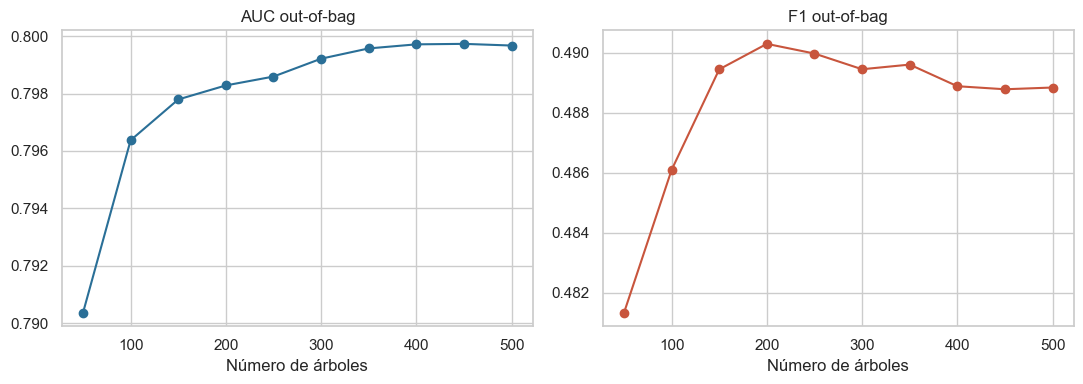

 arboles  f1_oob  auc_oob
      50  0.4813   0.7904
     100  0.4861   0.7964
     150  0.4894   0.7978
     200  0.4903   0.7983
     250  0.4900   0.7986
     300  0.4894   0.7992
     350  0.4896   0.7996
     400  0.4889   0.7997
     450  0.4888   0.7997
     500  0.4888   0.7997


In [17]:
maximo_rf = mejor_rf["max_features"] if mejor_rf["max_features"] == "sqrt" else float(mejor_rf["max_features"])
hoja_rf = int(mejor_rf["min_samples_leaf"])

curva_rf = RandomForestClassifier(max_features=maximo_rf, min_samples_leaf=hoja_rf, class_weight="balanced_subsample",
                                  oob_score=True, warm_start=True, n_jobs=-1, random_state=RANDOM_STATE)
filas = []
for arboles in range(50, 501, 50):
    curva_rf.set_params(n_estimators=arboles).fit(Xt_rf, y_train)
    f1_oob, auc_oob, _ = resumen_oob(curva_rf)
    filas.append({"arboles": arboles, "f1_oob": f1_oob, "auc_oob": auc_oob})
curva_rf = pd.DataFrame(filas)

fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
ejes[0].plot(curva_rf["arboles"], curva_rf["auc_oob"], marker="o", color="#2a6f97")
ejes[0].set_title("AUC out-of-bag")
ejes[1].plot(curva_rf["arboles"], curva_rf["f1_oob"], marker="o", color="#c8553d")
ejes[1].set_title("F1 out-of-bag")
for eje in ejes:
    eje.set_xlabel("Número de árboles")
plt.tight_layout()
guardar("04_rf_curva_oob")
plt.show()
print(curva_rf.round(4).to_string(index=False))

**Lectura.** El AUC OOB deja de mejorar entre 300 y 400 árboles (0,799 a 0,800) y el F1 OOB se estabiliza
desde los 150 (entre 0,489 y 0,490). Los 300 árboles elegidos están en la meseta, y agregar más solo
encarecería el modelo.

### Efecto de la ponderación (con OOB)

Con la mejor combinación comparé el bosque ponderado contra uno sin ponderar usando la misma métrica
OOB. No hizo falta validación cruzada porque el OOB ya es una estimación fuera de muestra.

In [18]:
filas = []
for etiqueta, peso in [("sin ponderar", None), ("balanced_subsample", "balanced_subsample")]:
    bosque = ajustar_rf(maximo_rf, hoja_rf, peso=peso)
    oob = np.nan_to_num(bosque.oob_decision_function_[:, 1], nan=0.0)
    filas.append({"ponderación": etiqueta, "f1_oob": f1_score(y_train, oob > 0.5),
                  "recall_oob": recall_score(y_train, oob > 0.5), "precision_oob": precision_score(y_train, oob > 0.5),
                  "auc_oob": roc_auc_score(y_train, oob)})
pd.DataFrame(filas).set_index("ponderación").round(4)

,f1_oob,recall_oob,precision_oob,auc_oob
ponderación,,,,
sin ponderar,0.3388,0.2297,0.6450,0.7990
balanced_subsample,0.4894,0.5318,0.4534,0.7992


**Lectura.** Sin ponderar, el bosque predice muy pocos contratadores (recall OOB de 0,230 y F1 de 0,339).
Con `balanced_subsample` el F1 sube a 0,489 y el recall a 0,532. El AUC es igual en ambos (0,799), lo que
indica que la ponderación mueve el punto de operación pero no cambia lo bien que el bosque ordena a los
clientes.

### Modelo final, costo, OOB frente a prueba y estabilidad

Ajusté el modelo final como `Pipeline` completo con un solo núcleo para medir el costo, y elegí su umbral
con las probabilidades out-of-bag del propio bosque, que no dependen del conjunto de prueba. Cerré el bloque
con dos verificaciones. La primera compara la estimación OOB con el resultado en prueba, ya que si el OOB
es un buen estimador las dos cifras deben quedar cerca. La segunda mide la estabilidad, para lo que
reentrené el bosque con cinco semillas distintas y medí cuánto cambian el F1 y el AUC en prueba.

In [19]:
def construir_rf():
    return Pipeline([
        ("prep", prep_sin_escalar()),
        ("clf", RandomForestClassifier(n_estimators=300, max_features=maximo_rf, min_samples_leaf=hoja_rf,
                                       class_weight="balanced_subsample", oob_score=True, n_jobs=1,
                                       random_state=RANDOM_STATE))])

rf_final, segundos_rf, rango_rf = ajustar_midiendo(construir_rf)

f1_oob_final, auc_oob_final, acc_oob_final = resumen_oob(rf_final.named_steps["clf"])
puntaje_oob_rf = np.nan_to_num(rf_final.named_steps["clf"].oob_decision_function_[:, 1], nan=0.0)
umbral_rf, f1_oob_umbral = umbral_optimo(y_train, puntaje_oob_rf)
print(f"Umbral elegido por OOB: {umbral_rf:.3f} (F1 OOB con ese umbral {f1_oob_umbral:.4f})")
registrar("RandomForest", rf_final, segundos_rf, 5, umbral_rf, 0.5,
          extra={"rango_entrenamiento_s": rango_rf, "parametros": {"max_features": str(maximo_rf), "min_samples_leaf": hoja_rf, "n_estimators": 300},
                 "oob": {"f1": f1_oob_final, "roc_auc": auc_oob_final, "accuracy": acc_oob_final}})
print(f"OOB -> F1 {f1_oob_final:.4f} | AUC {auc_oob_final:.4f}   frente a   prueba -> "
      f"F1 {resultados['RandomForest']['test']['f1']:.4f} | AUC {resultados['RandomForest']['test']['roc_auc']:.4f}")

Umbral elegido por OOB: 0.480 (F1 OOB con ese umbral 0.4907)


RandomForest: umbral ajustado 0.480 (por defecto 0.5) | F1 en prueba con el umbral por defecto 0.5004
RandomForest: entrenamiento 34.67 s | predicción 0.813 s
  test -> accuracy 0.8702 | precision 0.4545 | recall 0.5473 | F1 0.4966 | AUC 0.8083
  train (muestra) -> F1 0.7125 | AUC 0.9679
  IC 95 % F1 0.4710 a 0.5206 | captura top 20 % 0.632
OOB -> F1 0.4894 | AUC 0.7992   frente a   prueba -> F1 0.4966 | AUC 0.8083


**Lectura.** El umbral elegido por OOB (0,480) casi coincide con el de 0,5, y en prueba el F1 fue 0,497,
apenas por debajo del 0,500 que habría dado el umbral por defecto. Es un resultado honesto, porque el
umbral se eligió sin mirar la prueba y la diferencia está dentro del ruido. El Random Forest obtiene el
mejor AUC empatado con XGBoost (0,808) y la estimación OOB (F1 de 0,489 y AUC de 0,799) quedó cerca del
resultado en prueba, lo que confirma que el OOB sirve como validación. Pero el bosque tiene la mayor
brecha de sobreajuste (AUC de 0,968 sobre entrenamiento contra 0,808 en prueba, y F1 de 0,712 contra
0,497), porque los árboles profundos memorizan y el promedio solo corrige parte de ese efecto. Entrenó en
unos 35 segundos con un solo núcleo y predijo en menos de un segundo.

             f1     auc
semilla                
1        0.4979  0.8075
7        0.5017  0.8069
21       0.4976  0.8078
42       0.4966  0.8083
99       0.5009  0.8073

Media: {'f1': 0.4989, 'auc': 0.8076} | Desviación: {'f1': 0.0022, 'auc': 0.0005}

 balance         0.1258
dia_del_anio    0.1232
age             0.1091
poutcome        0.0827
day             0.0824
month           0.0693
contact         0.0678
job             0.0618
campaign        0.0493
pdays           0.0417
dtype: float64


Gráfico guardado: C:\Users\USUARIO\Documents\6_SEMESTRE\MACHINE LEARNING\Bank_Marketing\bank_marketing\splits\04_rf_importancia.png


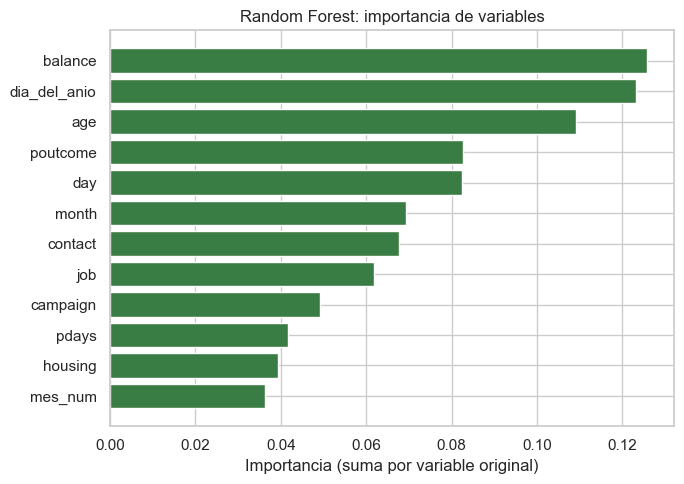

In [20]:
Xt_prueba_rf = preparador_rf.transform(X_test)
filas = []
for semilla in [1, 7, 21, 42, 99]:
    bosque = ajustar_rf(maximo_rf, hoja_rf, semilla=semilla)
    proba = bosque.predict_proba(Xt_prueba_rf)[:, 1]
    filas.append({"semilla": semilla, "f1": f1_score(y_test, proba > umbral_rf), "auc": roc_auc_score(y_test, proba)})
estabilidad_rf = pd.DataFrame(filas).set_index("semilla")
print(estabilidad_rf.round(4))
print("\nMedia:", estabilidad_rf.mean().round(4).to_dict(), "| Desviación:", estabilidad_rf.std().round(4).to_dict())
resultados["RandomForest"]["estabilidad_semillas"] = {"f1_media": float(estabilidad_rf["f1"].mean()),
    "f1_desv": float(estabilidad_rf["f1"].std()), "auc_media": float(estabilidad_rf["auc"].mean()),
    "auc_desv": float(estabilidad_rf["auc"].std())}

importancia_rf = importancia_por_variable(rf_final.named_steps["prep"], rf_final.named_steps["clf"].feature_importances_)
resultados["RandomForest"]["importancia"] = {k: float(v) for k, v in importancia_rf.items()}
persistir()
print("\n", importancia_rf.head(10).round(4))
graficar_importancia(importancia_rf, "Random Forest: importancia de variables", "04_rf_importancia", "#3a7d44")

**Lectura.** Con cinco semillas distintas el F1 en prueba varía entre 0,497 y 0,502 (desviación de
0,002) y el AUC prácticamente no cambia (desviación de 0,0005). El bosque es muy estable frente a la
aleatoriedad del remuestreo. En importancia de variables aparecen primero `balance` (12,6 %),
`dia_del_anio` (12,3 %), `age` (10,9 %) y `poutcome` (8,3 %). Esta medida (reducción de impureza)
favorece a las variables numéricas con muchos valores distintos, porque ofrecen más umbrales posibles, y
por eso `balance` y `age` aparecen más arriba que en el árbol y en el boosting.


**Criterios de selección del bloque.** Dentro del bosque, la combinación se eligió por F1 OOB y el umbral
por OOB, sin gastar datos de validación. Como modelo, el bosque se juzga con cuatro criterios. En
rendimiento es segundo en F1 (0,497) y empata el mejor AUC (0,808). En estabilidad es excelente frente a
la semilla, pero tiene la mayor brecha entre entrenamiento y prueba. En costo es intermedio, con decenas de
segundos de entrenamiento y menos de un segundo de predicción. En interpretabilidad solo ofrece
importancias de variables, no reglas.

# Bloque 4: XGBoost (boosting)

### Decisiones de diseño

**Qué cambia respecto al bagging.** Un bosque entrena árboles independientes y los promedia; el
boosting entrena árboles **en secuencia**, cada uno corrigiendo los errores del conjunto anterior.
Eso reduce el sesgo (puede construir fronteras que un árbol suelto no alcanza) pero, si se deja correr
sin freno, acaba memorizando el ruido. Por eso aquí el control del sobreajuste es parte central del
diseño.

**Hiperparámetros.** `learning_rate` (cuánto aporta cada árbol: valores bajos exigen más árboles pero
generalizan mejor), `max_depth` (complejidad de cada árbol; en boosting conviene que sean poco
profundos), `min_child_weight` (cuánta evidencia mínima necesita una hoja, otra forma de frenar el
sobreajuste) y `n_estimators`, que **no se busca en rejilla** sino con *early stopping*. `subsample` y
`colsample_bytree` se fijan en 0,8, que agrega aleatoriedad y regulariza.

**Early stopping.** Separé de entrenamiento una partición interna de validación (15 %, estratificada).
Entrené con un número de árboles muy alto (3000) y detuve el entrenamiento cuando el AUC de validación
no mejoró durante 50 rondas, con lo que el mejor número de árboles quedó registrado. El conjunto de
prueba no intervino.

**Ponderación.** `scale_pos_weight` igual a la razón entre clases (aproximadamente 7,55) es el
equivalente de `class_weight="balanced"` en XGBoost.

**Selección y umbral.** El early stopping de cada combinación usó AUC, y entre combinaciones también
elegí la de mayor AUC de validación, porque mide qué tan bien ordena a los clientes sin depender del
umbral. Después elegí el umbral que maximiza el F1 en esa misma partición de validación.

**Modelo final.** Reentrené sobre todo el entrenamiento con el número de árboles encontrado
multiplicado por 1,1, porque el modelo final ve un 17 % más de datos que el de la búsqueda.

In [21]:
preparador_xgb = prep_sin_escalar().fit(X_train)
Xt_xgb = preparador_xgb.transform(X_train)
Xt_prueba_xgb = preparador_xgb.transform(X_test)
Xi, Xv, yi, yv = train_test_split(Xt_xgb, y_train, test_size=0.15, stratify=y_train, random_state=RANDOM_STATE)

def ajustar_xgb(tasa, profundidad, peso_pos, hijo=1):
    modelo = XGBClassifier(n_estimators=3000, learning_rate=tasa, max_depth=profundidad, min_child_weight=hijo, subsample=0.8,
                           colsample_bytree=0.8, scale_pos_weight=peso_pos, eval_metric="auc",
                           early_stopping_rounds=50, tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE)
    modelo.fit(Xi, yi, eval_set=[(Xi, yi), (Xv, yv)], verbose=False)
    return modelo

filas, modelos_busqueda = [], {}
for tasa in [0.03, 0.1, 0.3]:
    for profundidad in [3, 4, 6]:
        for hijo in [1, 5]:
            inicio = time.perf_counter()
            modelo = ajustar_xgb(tasa, profundidad, peso_positivo, hijo)
            proba = modelo.predict_proba(Xv)[:, 1]
            filas.append({"learning_rate": tasa, "max_depth": profundidad, "min_child_weight": hijo,
                          "arboles_optimos": modelo.best_iteration + 1, "auc_validacion": modelo.best_score,
                          "f1_validacion": f1_score(yv, proba > 0.5), "segundos": time.perf_counter() - inicio})
            modelos_busqueda[(tasa, profundidad, hijo)] = modelo

busqueda_xgb = pd.DataFrame(filas)
print(busqueda_xgb.round(4).to_string(index=False))
mejor_xgb = busqueda_xgb.loc[busqueda_xgb["auc_validacion"].idxmax()]
print("\nMejor combinación según AUC de validación:")
print(mejor_xgb.round(4).to_string())

 learning_rate  max_depth  min_child_weight  arboles_optimos  auc_validacion  f1_validacion  segundos
          0.03          3                 1              665          0.8176         0.4645   17.1073
          0.03          3                 5              551          0.8175         0.4611   12.2202
          0.03          4                 1              446          0.8208         0.4681   13.3383
          0.03          4                 5              517          0.8210         0.4655   15.5039
          0.03          6                 1              266          0.8183         0.4738    9.8585
          0.03          6                 5              266          0.8191         0.4705    6.8692
          0.10          3                 1              256          0.8190         0.4688    5.8439
          0.10          3                 5              249          0.8167         0.4637    5.5576
          0.10          4                 1               93          0.8143      

**Lectura.** Las dieciocho combinaciones tienen un AUC de validación parecido (0,809 a 0,821). Lo que sí
cambia mucho es la cantidad de árboles que pide el early stopping. Con `learning_rate = 0,03` llega a 665
árboles si la profundidad es 3, y con 0,3 y profundidad 6 se detiene en 21. La mejor combinación por AUC es
`learning_rate = 0,03`, `max_depth = 4` y `min_child_weight = 5`, con 517 árboles. La tasa baja necesita
más árboles para llegar a una calidad similar, pero es la que mejor generaliza.

Umbral elegido en la partición de validación: 0.627 (F1 de validación 0.5190)


Gráfico guardado: C:\Users\USUARIO\Documents\6_SEMESTRE\MACHINE LEARNING\Bank_Marketing\bank_marketing\splits\04_xgb_early_stopping.png


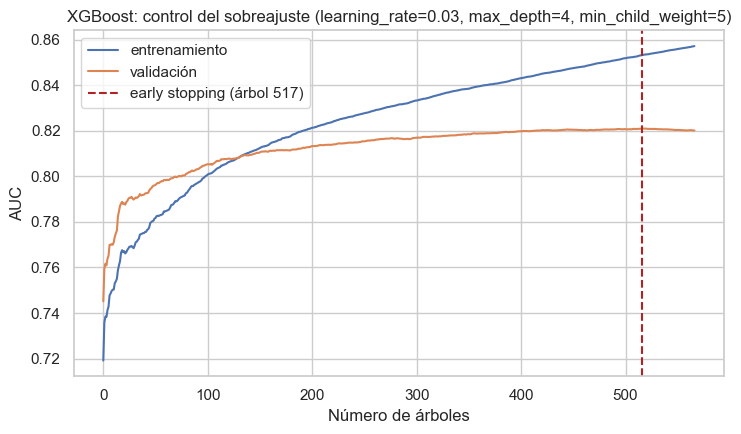

In [22]:
tasa_xgb = float(mejor_xgb["learning_rate"])
profundidad_xgb = int(mejor_xgb["max_depth"])
hijo_xgb = int(mejor_xgb["min_child_weight"])
modelo_elegido = modelos_busqueda[(tasa_xgb, profundidad_xgb, hijo_xgb)]
umbral_xgb, f1_val_xgb = umbral_optimo(yv, modelo_elegido.predict_proba(Xv)[:, 1])
print(f"Umbral elegido en la partición de validación: {umbral_xgb:.3f} (F1 de validación {f1_val_xgb:.4f})")
curvas = modelo_elegido.evals_result()
mejor_ronda = modelo_elegido.best_iteration

plt.figure(figsize=(7.5, 4.5))
plt.plot(curvas["validation_0"]["auc"], label="entrenamiento")
plt.plot(curvas["validation_1"]["auc"], label="validación")
plt.axvline(mejor_ronda, color="firebrick", linestyle="--", label=f"early stopping (árbol {mejor_ronda + 1})")
plt.xlabel("Número de árboles")
plt.ylabel("AUC")
plt.title(f"XGBoost: control del sobreajuste (learning_rate={tasa_xgb}, max_depth={profundidad_xgb}, min_child_weight={hijo_xgb})")
plt.legend()
plt.tight_layout()
guardar("04_xgb_early_stopping")
plt.show()

**Lectura.** La curva de entrenamiento sigue subiendo (AUC cerca de 0,86) mientras la de validación se
aplana en 0,821 y deja de mejorar después del árbol 517, que es donde se detiene el entrenamiento. La
distancia entre ambas curvas es el sobreajuste que el early stopping evita seguir ampliando. En esa misma
partición de validación elegí el umbral de 0,627, con el que el F1 de validación sube de 0,466 a 0,519.

### Efecto de la ponderación

Con la mejor combinación volví a correr el early stopping sin ponderar (`scale_pos_weight=1`) y comparé
en la misma partición de validación.

In [23]:
filas = []
for etiqueta, peso in [("sin ponderar (1)", 1.0), (f"scale_pos_weight ({peso_positivo:.2f})", peso_positivo)]:
    modelo = ajustar_xgb(tasa_xgb, profundidad_xgb, peso, hijo_xgb)
    proba = modelo.predict_proba(Xv)[:, 1]
    filas.append({"ponderación": etiqueta, "f1": f1_score(yv, proba > 0.5), "recall": recall_score(yv, proba > 0.5),
                  "precision": precision_score(yv, proba > 0.5), "auc": roc_auc_score(yv, proba)})
pd.DataFrame(filas).set_index("ponderación").round(4)

,f1,recall,precision,auc
ponderación,,,,
sin ponderar (1),0.3498,0.2346,0.6866,0.8164
scale_pos_weight (7.55),0.4655,0.6472,0.3634,0.8210


**Lectura.** `scale_pos_weight` sube el recall de 0,235 a 0,647 y el F1 de 0,350 a 0,466, y además
mejora un poco el AUC (de 0,816 a 0,821). Conservé la ponderación.

### Modelo final, costo y estabilidad

Ajusté el `Pipeline` completo con el número de árboles ya fijado (sin early stopping, porque no hay
partición de validación en este paso) y un solo núcleo. Después lo reentrené con cinco semillas para
medir la estabilidad.

In [24]:
arboles_finales = int((mejor_ronda + 1) * 1.1)
parametros_xgb = dict(n_estimators=arboles_finales, learning_rate=tasa_xgb, max_depth=profundidad_xgb,
                      min_child_weight=hijo_xgb, subsample=0.8,
                      colsample_bytree=0.8, scale_pos_weight=peso_positivo, tree_method="hist")

def construir_xgb():
    return Pipeline([
        ("prep", prep_sin_escalar()),
        ("clf", XGBClassifier(**parametros_xgb, n_jobs=1, random_state=RANDOM_STATE))])

xgb_final, segundos_xgb, rango_xgb = ajustar_midiendo(construir_xgb)

registrar("XGBoost", xgb_final, segundos_xgb, 5, umbral_xgb, 0.5,
          extra={"rango_entrenamiento_s": rango_xgb, "parametros": {"learning_rate": tasa_xgb, "max_depth": profundidad_xgb,
                                "min_child_weight": hijo_xgb, "n_estimators": arboles_finales,
                                "arboles_early_stopping": int(mejor_ronda + 1), "subsample": 0.8, "colsample_bytree": 0.8,
                                "scale_pos_weight": peso_positivo}})

XGBoost: umbral ajustado 0.627 (por defecto 0.5) | F1 en prueba con el umbral por defecto 0.4609
XGBoost: entrenamiento 4.87 s | predicción 0.114 s
  test -> accuracy 0.8728 | precision 0.4634 | recall 0.5510 | F1 0.5035 | AUC 0.8083
  train (muestra) -> F1 0.5157 | AUC 0.8412
  IC 95 % F1 0.4783 a 0.5269 | captura top 20 % 0.635


**Lectura.** XGBoost obtiene el mejor F1 del experimento (0,503) y empata el mejor AUC (0,808). El umbral
ajustado fue el que más aportó en este modelo, porque con 0,5 el F1 habría sido 0,461. Con el umbral de
0,627 el modelo marca a menos clientes, pero con más precisión. Entrena en unos 5 segundos con un solo núcleo, unas siete veces más rápido que el
Random Forest y unas veinte veces más rápido que el SVM, y predice los 9.043 clientes en una décima de
segundo. Su brecha de sobreajuste es pequeña (F1 de 0,516 en entrenamiento contra 0,503 en prueba).

             f1     auc
semilla                
1        0.5013  0.8078
7        0.5072  0.8082
21       0.5063  0.8080
42       0.5074  0.8087
99       0.5028  0.8080

Media: {'f1': 0.505, 'auc': 0.8081} | Desviación: {'f1': 0.0028, 'auc': 0.0003}

 poutcome        0.2948
month           0.2637
contact         0.1332
job             0.0729
housing         0.0488
marital         0.0412
education       0.0263
dia_del_anio    0.0181
mes_num         0.0162
loan            0.0160
dtype: float64


Gráfico guardado: C:\Users\USUARIO\Documents\6_SEMESTRE\MACHINE LEARNING\Bank_Marketing\bank_marketing\splits\04_xgb_importancia.png


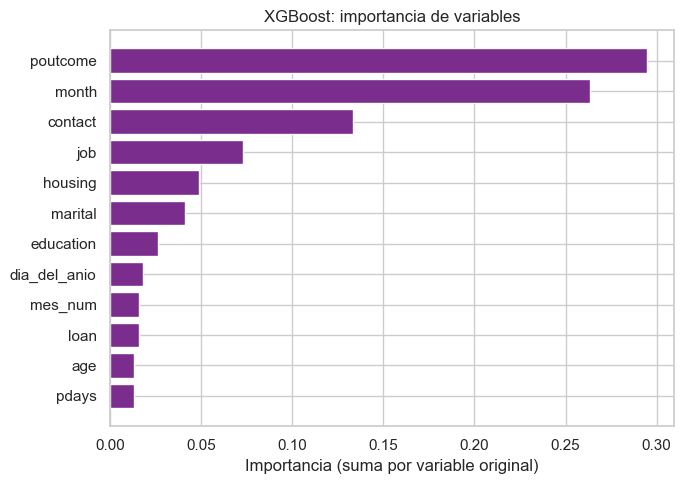

In [25]:
filas = []
for semilla in [1, 7, 21, 42, 99]:
    modelo = XGBClassifier(**parametros_xgb, n_jobs=-1, random_state=semilla).fit(Xt_xgb, y_train)
    proba = modelo.predict_proba(Xt_prueba_xgb)[:, 1]
    filas.append({"semilla": semilla, "f1": f1_score(y_test, proba > umbral_xgb), "auc": roc_auc_score(y_test, proba)})
estabilidad_xgb = pd.DataFrame(filas).set_index("semilla")
print(estabilidad_xgb.round(4))
print("\nMedia:", estabilidad_xgb.mean().round(4).to_dict(), "| Desviación:", estabilidad_xgb.std().round(4).to_dict())
resultados["XGBoost"]["estabilidad_semillas"] = {"f1_media": float(estabilidad_xgb["f1"].mean()),
    "f1_desv": float(estabilidad_xgb["f1"].std()), "auc_media": float(estabilidad_xgb["auc"].mean()),
    "auc_desv": float(estabilidad_xgb["auc"].std())}

importancia_xgb = importancia_por_variable(xgb_final.named_steps["prep"], xgb_final.named_steps["clf"].feature_importances_)
resultados["XGBoost"]["importancia"] = {k: float(v) for k, v in importancia_xgb.items()}
persistir()
print("\n", importancia_xgb.head(10).round(4))
graficar_importancia(importancia_xgb, "XGBoost: importancia de variables", "04_xgb_importancia", "#7b2d8e")

**Lectura.** Con cinco semillas el F1 en prueba varía entre 0,501 y 0,507 (desviación de 0,003) y el AUC
entre 0,808 y 0,809. Es tan estable como el bosque. En importancia dominan `poutcome` (29,5 %), `month`
(26,4 %) y `contact` (13,3 %), las tres variables de contexto de la campaña. Las variables numéricas
pesan poco en este modelo, al contrario de lo que ocurre en el bosque.


**Criterios de selección del bloque.** Dentro del boosting, el número de árboles lo fijó el early
stopping, la combinación se eligió por AUC de validación y el umbral por F1 en la misma partición. Como
modelo, XGBoost se juzga con cuatro criterios. En rendimiento es el primero en F1 y empata el mejor AUC.
En estabilidad varía poco con la semilla y su brecha de sobreajuste es pequeña. En costo es el segundo más
barato, con un entrenamiento de pocos segundos. En interpretabilidad ofrece importancias claras, aunque no
reglas legibles.

## Cierre del notebook

Reuní en una tabla los cuatro modelos y la línea base con todo lo medido en este notebook. El notebook 05
parte de estos mismos archivos para construir la comparación, las figuras y las conclusiones.

In [26]:
filas = []
for nombre, r in resultados.items():
    filas.append({"modelo": nombre, **{k: round(v, 4) for k, v in r["test"].items()},
                  "t_entrenamiento_s": round(r["tiempo_entrenamiento_s"], 3),
                  "t_prediccion_s": round(r["tiempo_prediccion_s"], 4)})
pd.DataFrame(filas).set_index("modelo")

,accuracy,precision,recall,f1,roc_auc,t_entrenamiento_s,t_prediccion_s
modelo,,,,,,,
Baseline,0.8830,0.0000,0.0000,0.0000,0.5000,0.004,0.0001
SVM,0.8704,0.4531,0.5208,0.4846,0.7907,96.642,44.3821
Arbol,0.8796,0.4852,0.4792,0.4822,0.7592,0.679,0.0702
RandomForest,0.8702,0.4545,0.5473,0.4966,0.8083,34.675,0.8126
XGBoost,0.8728,0.4634,0.5510,0.5035,0.8083,4.874,0.1141


**Lectura.** XGBoost lidera en F1 y empata con el Random Forest en AUC. El SVM y el árbol quedan atrás
en F1 por poco, pero el árbol queda claramente atrás en AUC. El costo se ordena distinto. El árbol es el
más barato, XGBoost le sigue, el Random Forest cuesta unas siete veces más que XGBoost y el SVM es el más
caro, sobre todo al predecir. El notebook 05 pondera esas dos dimensiones.